In [2]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [157]:
# Instance Attributes - Variables defined on self inside __init__ or other methods. 
# Class Attributes - Variables defined directly in the class body (outside __init__). These are shared across all instances of that class.
# Instance Methods - Standard functions inside a class that take self as the first argument. They can read and mutate instance state (self.x).
# Special Methods - Double-underscore methods like __init__, __call__, and __add__ hook directly into Python operators and syntax behaviors.

In [ ]:
# micrograd is an autograd engine for educational purposes only. 
# micrograd functions the same when compared to PyTorch's loss.backward(). 
# Andrej demonstrates that an automatic backward differentiation engine can be written in few tens lines of understandable code. 
# we will use PyTorch rather than micrograd in exemplar and real nn applications. 
# micrograd wraps scalars in individual Value objs, PyTorch computes tensors in parallel which is much more efficient. 

In [ ]:
# Neuron - Takes input and weight pairs xi, wi, a bias b and an activation function a(). 
# Calculates output = a(sum(xi * wi) + b) (a() is tanh() here.)

# loss function - Sum of mean square difference between predicted outcome and actual outcome.
# Evaluate loss.backward(). If p.grad > 0, increasing p decreases loss. Vice versa for p.grad < 0. 
# when loss is small, nn is doing what user asks. 

# nn training - Let xs be training data sets and ys be known outputs. nn dials parameters in such that loss is minimised. 
# With dialed in parameters, nn can predict outcomes yi given new inputs xi. 

# MLP - Dictates how many distinct inputs xi should be accepted at once, the number of neurons in each hidden layer and how many hidden layers it posess,
# and the number of outputs in the final layer. e.g. MLP(3, [4, 4, 1]) accepts 3 xi that parse through 2 hidden layers of 4 neurons, and the nn outputs 1 Value obj.  

# Hidden layers - Width (# of neurons in a single hidden layer) affects working on many information simultaneously. 
# Depth (# of hidden layers) affects breaking complex problems (getting from x to y if relationship is non-trivial) into steps, 
# where each layer handles 1 step. 

In [126]:
class Value:
    """
    A class that defines addition, multiplicaiton and hyperbolic tangent operations as add, mul and tanh methods. 
    These are the only methods required to construct a neuron. 
    It also constructs an expression tree tracking parent Value objects of each Value obj and what operation created it.
    """
    def __init__(self, data, _children = (), _op='', label=''):
        """
        Takes argument data and stores it in an obj as self.data.
        _children: a tuple holding the parent Value objects that produced this Value.
        _op: a string representing the operation that produced this Value. 
        label: a label to distinguish different Value objs. 
        """
        self.data = data
        self.grad = 0.0 # derivative of final layer output Value wrt all Value objects before it. Default = 0.0
        self._backward = lambda: None # custom defined backward propagation function. Default = None
        self._prev = set(_children)
        self._op = _op
        self.label = label
        
    def __repr__(self):
        """
        The obj's value is returned (instead of its memory address).
        """
        return f"Value(data={self.data})"

    def __add__(self, other):
        """
        Takes two Value instances (self and other), adds their .data attributes together, 
        and returns a new Value obj with the sum as its data attribute. 
        + works on the float point attribute values - not between objs. 
        a+b == self.__add__(other)
        """
        other = other if isinstance(other, Value) else Value(other) # converts other to a Value object if it already isnt one
        out = Value(self.data + other.data, (self, other), '+')

        # define custom back propagation function for the add method
        # += in back propagation methods: gradients must add (instd of being overwritten) when two Value objs back propagate to the same child. 
        def _backward():
            self.grad += 1 * out.grad # out.grad contains chain rule from final output to this particular out Value. 
            other.grad += 1 * out.grad
        out._backward = _backward
        
        return out

    def __radd__(self, other): # other + self (uses __add__ method)
        return self + other

    def __mul__(self, other):
        """
        Takes two Value instances and multiply their .data attributes together,
        returns a new Value obj whose .data attribute contains the outcome. 
        """
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
            self.grad += out.grad * other.data
            other.grad += self.data * out.grad
        out._backward = _backward
        
        return out

    # Below is a demonstration that the tanh class can be broken down using math.exp
    # Or simply using math.tanh
    # math.tanh is more efficient (creates less Value objs) and more stable (e^(2x) might create overflow error if x is large).
    
    # def tanh(self):
    #     """
    #     Takes one Value instance and returns tanh of that Value. 
    #     """
    #     x = self.data
    #     t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    #     out = Value(t, (self, ), 'tanh')

    #     def _backward():
    #         self.grad += out.grad * (1-t**2) # local derivative of tanh
    #     out._backward = _backward
        
    #     return out

    def tanh(self):
        """
        tanh is the activation function. It maps logits to outputs in range +-1, signifying pos/neg response with varying degree of strength. 
        tanh is NON LINEAR. 
        d/dx tanh = 1-tanh^2, gradient is easy to calculate. 
        
        """
        
        x = self.data
        t = math.tanh(x) 
        out = Value(t, (self, ), 'tanh')
        
        def _backward():
          self.grad += (1 - t**2) * out.grad
        out._backward = _backward
    
        return out

    def __neg__(self):
        return self * -1
    
    def __sub__(self, other):
        return self + (-other)
    
    def __rsub__(self, other):
        # float - Value
        return other + (-self)

    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')
        
        def _backward():
            self.grad += other * (self.data ** (other - 1)) * out.grad
        out._backward = _backward
        
        return out
        
    def backward(self):
        
        topo = []
        visited = set()
        
        def build_topo(v):
            """
            A topological sort function that visits each node from the output. 
            Orders Value objects in nodes such that every children comes before the parent nodes. 
            Orders of independent inputs (e.g. x1, x2, b) do not matter as long as above is true. 
            """
            # Inspect a node and adds it to the visited set.
            if v not in visited: 
                visited.add(v)
                # Inspect all of v's children until a child has no children left (start of digraph).
                for child in v._prev:
                    build_topo(child)
                topo.append(v) # Append v after processing all of its children. 
                # Nodes at the start of graph are appended first! They have no children so they are processed first!
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()
                    

In [127]:
a = Value(2, label='a')
b = Value(-3, label='b')
c = Value(10, label='c')
e = a*b; e.label='e'
d = e + c; d.label='d'
f = Value(-2, label='f')
L = d * f; L.label='L'
d._prev, d._op

({Value(data=-6), Value(data=10)}, '+')

In [128]:
# Using directed graphs to visualise nodes 

from graphviz import Digraph

def trace(root):
    """
    Builds a set of all nodes and edges in a directed graph.
    """
    nodes, edges = set(), set()
    def build(v):
        """
        Adds a node v into the digraph if it is not present. 
        Builds edges from each children of v to v. 
        """
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format = 'svg', graph_attr = {'rankdir': 'LR'})
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # In each node, print node label, Value, and back propagation gradient
        dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape = 'record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

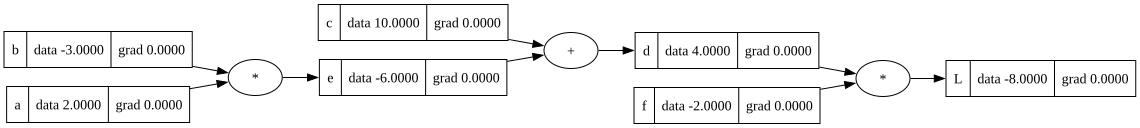

In [129]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a*b; e.label='e'
d = e + c; d.label='d'
L = d * f; L.label='L'

draw_dot(L)

In [130]:
# example neuron structure
"""
Input 1 ──[weight]──┐
                    │
Input 2 ──[weight]──┼──→ NEURON (weighted sum + bias + activation function) ──→ output
                    │
Input 3 ──[weight]──┘

Neuron accepts inputs and weights, evaluate an output using the bias and an activation function on the weighted input sum, 
and feeds them as input into other neurons. 

tanh output function maps raw outputs into range +-1.
pos/neg raw output = pos/neg response. raw output ~ 0 = weak response. 

weighted input sum - based on inputs and weights, how should the neuron respond. 
bias - before any information how strongly should the neuron respond. (prevent no response when raw output = 0)
"""
# neuron inputs x1, x2
x1 = Value(2.0, label='x1')
x2=Value(0.0, label='x2')
# weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# neuron bias
b = Value(6.7, label='b')
# x1w1 + x2w2 + b
x1w1 = x1 * w1; x1w1.label='x1w1'
x2w2 = x2 * w2; x2w2.label='x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1 + x2w2'
n = x1w1x2w2 + b; n.label = 'n'
# apply activation function tanh (arb value -> between +-1)
o = n.tanh(); o.label = 'o'

In [131]:
# the topological sort function was outside of the Value class, it has now been moved into it and hashed out here. 

# topo = []
# visited = set()

# def build_topo(v):
#     """
#     A topological sort function that visits each node from the output. 
#     Orders Value objects in nodes such that every children comes before the parent nodes. 
#     Orders of independent inputs (e.g. x1, x2, b) do not matter as long as above is true. 
#     """
#     # Inspect a node and adds it to the visited set.
#     if v not in visited: 
#         visited.add(v)
#         # Inspect all of v's children until a child has no children left (start of digraph).
#         for child in v._prev:
#             build_topo(child)
#         topo.append(v) # Append v after processing all of its children. 
#         # Nodes at the start of graph are appended first! They have no children so they are processed first!
# build_topo(o)
# topo

In [132]:
o.backward() # instd of setting o.grad = 1 and parsing nodes through above hashed code

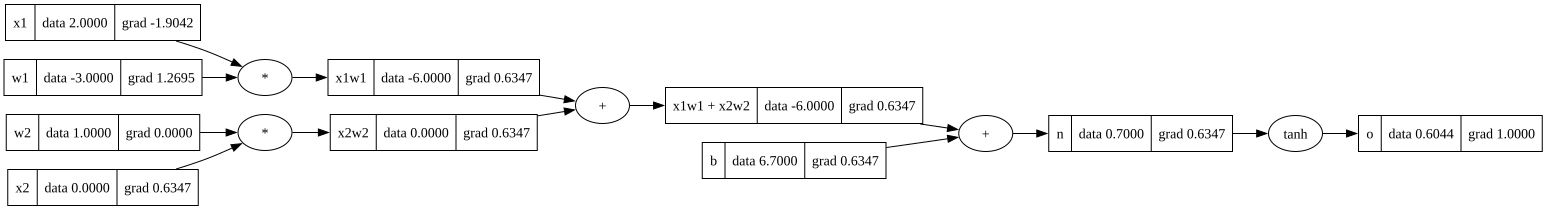

In [133]:
draw_dot(o)

In [134]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.


In [135]:
# above example using pytorch
# pytorch automatically tracks every operation and auto calculates gradients. 
# we won't use micrograd when implementing back propagation in later nns. 
import torch

# tensors - multi dimensional arrays (matrices) of numbers. 
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True # .double() - double precision (float64 inst of 32)
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward() # reverse topo sort from o

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [155]:
# Building a neural network
class Neuron:
    """
    Constructs a neuron using given inputs and generated bias and weights. 
    The neuron takes input xi and sums wi * xi pairs and the bias, tanh activation function acts on the sum to give the output. 
    The inputs of latter layers are the outputs of the layer before it. 
    """
    def __init__(self, nin): # nin - # of inputs
        # initialise a weight for each input and a bias as Value objects. 
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
    
    def __call__(self, x):
        # combine weight, bias and inputs - sum of w * x + b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out
    
    # construct a list of weights and biases as the parameters list
    def parameters(self):
        return self.w + [self.b] # list obj + list obj


class Layer:
    """
    Constructs layers of neurons - # of layers depend on nout. 
    Feeds inputs xi to all layers and returns all outputs (each neuron has different wi and b).
    """
    def __init__(self, nin, nout): # nout - # of outputs in a single layer. 
        self.neurons = [Neuron(nin) for _ in range(nout)]
    
    def __call__(self, x):
        outs = [n(x) for n in self.neurons] # execute n(x) (neuron.__call__) for each neuron obj in self.neurons 
        return outs[0] if len(outs) == 1 else outs

    # for each neuron in this layer, append all parameters from the neurons to the parameters list
    def parameters(self):
        return [p for neuron in self.neurons for p in neuron.parameters()]
        # parameters.append(p) followed by 2 nested for loops (outer first)
        # neuron.parameters() generate a list that can be parsed through

class MLP:
    """
    Multi-layer Perceptron - chaining outputs of neurons to inputs to other neurons. 
    """
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
        
    def __call__(self, x):
        for layer in self.layers:
          x = layer(x)
        return x
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
        # layer.parameters() generate another list too

In [151]:
# example nn
x = [Value(2.0), Value(3.0), Value(-1.0)] # 3 inputs
n = MLP(3, [4, 4, 1]) # 2 hidden layers of 4 neurons, 1 final output
n(x)

Value(data=0.4712704607062278)

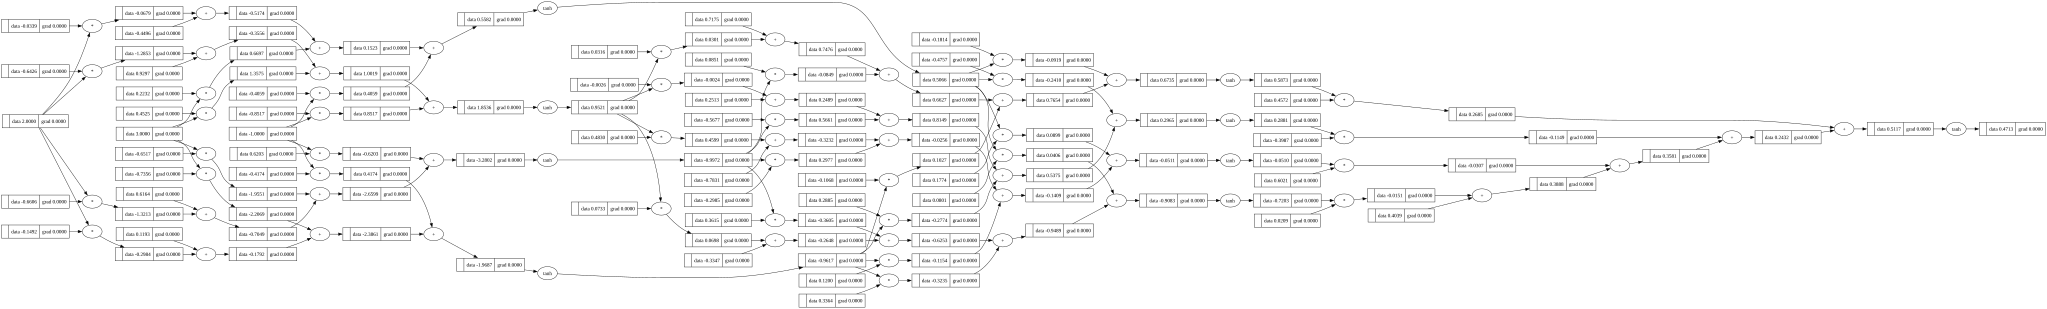

In [152]:
draw_dot(n(x))

In [153]:
# examplar data set
# inputs and their respective desired target outputs
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]
ys = [Value(y) for y in ys]

# for each row of xs, compute the output of a nn with MLP(3, [4, 4, 1]) as defined above. 
#ypred = [n(x) for x in xs]
#ypred

In [158]:
# loss - mean square loss between y's ground truth (ys) and ypred. 
# used as a performance indicator
# n - our MLP (n = MLP(3, [4, 4, 1]))

for k in range(30):
    # forward pass
    ypred = [n(x) for x in xs]
    # zip ys and ypred, iterate through to obtain pairwise diffs, and sum the squared diffs. 
    loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
    
    # backward pass
    for p in n.parameters(): # MLP accesses each Layer's parameters, each layer access is neuron's weights and biases
        p.grad = 0.0 # wipe old gradient (self.grad += fix above bricks if not wiped)
    loss.backward() # call backward propagation function on ms. loss - calculate loss' gradient wrt all Value obj parameters (biases and weights)
    
    # calculate new outputs using updated weights and biases
    # positive p.grad = increasing p.data increases loss -> decrease p.data by 0.1
    # negative p.grad = decreasing p.data increases loss -> increase p.data by 0.1
    for p in n.parameters():
        p.data += -0.1 * p.grad # reversed calculation 
    
    print(k, loss.data) # index of optimisation pass; mean square loss.

print(ypred) # optimised prediction outputs with dialed in parameters. 

0 0.013967472632991676
1 0.013469130366047702
2 0.01300373209761177
3 0.012568171736583533
4 0.012159717961249756
5 0.011775959706307161
6 0.011414760854495606
7 0.011074222375038183
8 0.010752650523601016
9 0.010448530004652406
10 0.010160501218564846
11 0.009887340888396464
12 0.009627945496687199
13 0.009381317069494443
14 0.009146550929779125
15 0.00892282511004923
16 0.00870939116860663
17 0.00850556619768171
18 0.008310725847378738
19 0.008124298218395741
20 0.007945758500255069
21 0.007774624251322372
22 0.007610451233023435
23 0.0074528297240353016
24 0.007301381251349501
25 0.00715575568438781
26 0.007015628646129583
27 0.0068806992017480546
28 0.006750687790766136
29 0.0066253343734076105
[Value(data=0.9717404119884541), Value(data=-0.9689608259349557), Value(data=-0.9472594087380629), Value(data=0.954374023127976)]
